In [1]:
!pip install -U structured-data-models

In [2]:
import torch
import sdm
import pandas as pd
import numpy as np

import random
import torch

import time
import gc

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt
import seaborn as sns

from sdm import TableTensor, Task
from sdm.models import (
    TabICLv2,
    TabFM,
    KumoTabular
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix
)

In [3]:
X_train = pd.read_csv('X_train_sel.csv')
X_test = pd.read_csv('X_test_sel.csv')
y_train = pd.read_csv('y_train_binary_sel.csv').iloc[:, 0]
y_test = pd.read_csv('y_test_binary_sel.csv').iloc[:, 0]

In [4]:
X_train = X_train.drop(columns=['sn'])
X_test = X_test.drop(columns=['sn'])

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1192, 19)
X_test: (298, 19)
y_train: (1192,)
y_test: (298,)


In [5]:
# Identify feature types
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [6]:
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [7]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Set the random seed for reproducibility
set_seed(42)

In [8]:
# Preprocessing
numeric_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [9]:
# Combine train and test features
X_all = pd.concat([X_train, X_test], ignore_index=True)

# Combine target: train labels + missing test labels
y_all = pd.concat([
    y_train.reset_index(drop=True),
    pd.Series([None] * len(X_test))
], ignore_index=True)

# Add target column
data = X_all.copy()
data['target'] = y_all

In [10]:
stypes = {}

for col in X_all.columns:
    if pd.api.types.is_numeric_dtype(X_all[col]):
        stypes[col] = "numerical"
    else:
        stypes[col] = "categorical"

stypes['target'] = "categorical"

In [11]:
table = TableTensor.from_columns(
    data.to_dict(orient='list'),
    stypes=stypes,
    device='cuda'
)

In [12]:
tabicl = TabICLv2(device="cuda")

out_icl = tabicl(
    x_context=table[:len(X_train)].drop_columns("target"),
    y_context=table[:len(X_train), "target"],
    x_query=table[len(X_train):].drop_columns("target"),
)

In [13]:
out_df = out_icl.to_pandas()
y_pred_tabicl = out_df.to_numpy().argmax(axis=1)
y_pred_proba_tabicl = out_df.iloc[:, 1].to_numpy()

In [14]:
n_train = len(X_train)
x_context = table[:n_train].drop_columns("target")
y_context = table[:n_train, "target"]
x_query = table[n_train:].drop_columns("target")

In [15]:
model_tabfm = TabFM(
    task=Task.classification,
    accept_license=True,
    device="cuda"
)

out_tabfm = model_tabfm(
    x_context=x_context,
    y_context=y_context,
    x_query=x_query
)

print(out_tabfm)
print(out_tabfm.to_pandas().head())

TableTensor(
  size=(298, 2),
  blocks={
    numerical (2): [0.0, 1.0],
  },
  device=cuda:0,
)
        0.0       1.0
0  0.007748  0.992252
1  0.998300  0.001700
2  0.001292  0.998708
3  0.590078  0.409923
4  0.000175  0.999825


In [16]:
out_df = out_tabfm.to_pandas()
y_pred_proba_tabfm = out_df.to_numpy()
y_pred_tabfm = out_df.to_numpy().argmax(axis=1)

In [17]:
model_kumo = KumoTabular(
    task=Task.classification,
    size="small",
    device="cuda"
)

out_kumo = model_kumo(
    x_context=x_context,
    y_context=y_context,
    x_query=x_query
)

print(out_kumo)
print(out_kumo.shape)

TableTensor(
  size=(298, 2),
  blocks={
    numerical (2): [0.0, 1.0],
  },
  device=cuda:0,
)
torch.Size([298, 2])


In [18]:
kumo_df = out_kumo.to_pandas()
y_pred_proba_kumo = kumo_df.to_numpy()
y_pred_kumo = kumo_df.to_numpy().argmax(axis=1)

In [19]:
y_pred_proba_tabfm = y_pred_proba_tabfm[:, 1]
y_pred_proba_kumo = y_pred_proba_kumo[:, 1]

In [20]:
evaluation_ptfm_binary = pd.DataFrame([
    {
        "Model": "Kumo",
        "Accuracy": accuracy_score(y_test, y_pred_kumo),
        "Precision": precision_score(y_test, y_pred_kumo, zero_division=0),
        "Recall": recall_score(y_test, y_pred_kumo, zero_division=0),
        "F1": f1_score(y_test, y_pred_kumo, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_pred_proba_kumo)
    },
    {
        "Model": "TabFM",
        "Accuracy": accuracy_score(y_test, y_pred_tabfm),
        "Precision": precision_score(y_test, y_pred_tabfm, zero_division=0),
        "Recall": recall_score(y_test, y_pred_tabfm, zero_division=0),
        "F1": f1_score(y_test, y_pred_tabfm, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_pred_proba_tabfm)
    },
    {
        "Model": "TabICL",
        "Accuracy": accuracy_score(y_test, y_pred_tabicl),
        "Precision": precision_score(y_test, y_pred_tabicl, zero_division=0),
        "Recall": recall_score(y_test, y_pred_tabicl, zero_division=0),
        "F1": f1_score(y_test, y_pred_tabicl, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_pred_proba_tabicl)
    }
])

evaluation_ptfm_binary = evaluation_ptfm_binary.round(4)

print(evaluation_ptfm_binary)

    Model  Accuracy  Precision  Recall      F1  ROC-AUC
0    Kumo    0.9060     0.9275  0.9366  0.9320   0.9605
1   TabFM    0.9060     0.9317  0.9317  0.9317   0.9587
2  TabICL    0.8792     0.8930  0.9366  0.9143   0.9527


In [21]:
evaluation_ptfm_binary.to_csv(
    "evaluation_ptfm_binary.csv",
    index=False
)

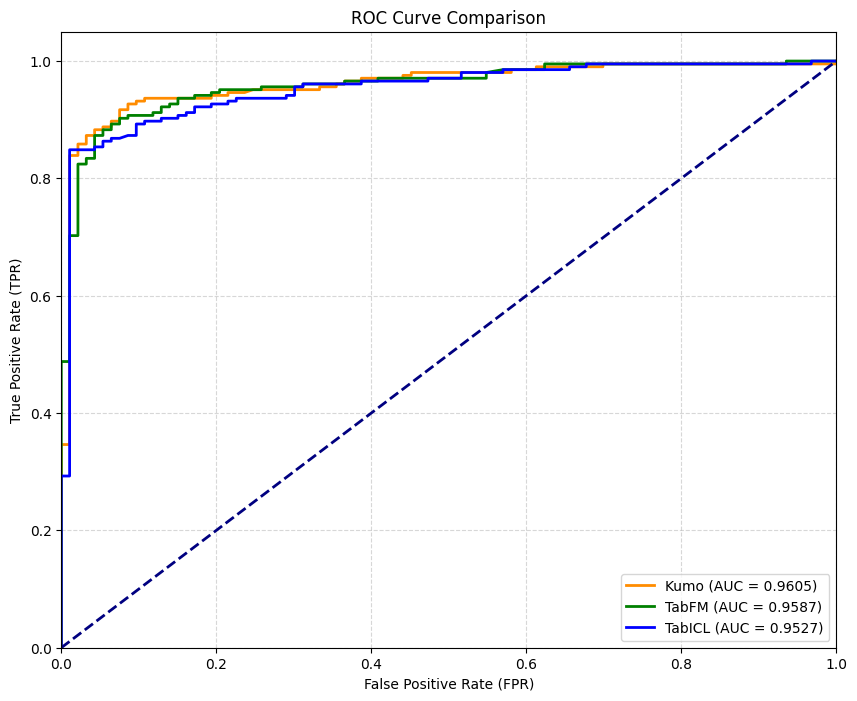

In [22]:
fpr_kumo, tpr_kumo, _ = roc_curve(y_test, y_pred_proba_kumo)
roc_auc_kumo = auc(fpr_kumo, tpr_kumo)

fpr_tabfm, tpr_tabfm, _ = roc_curve(y_test, y_pred_proba_tabfm)
roc_auc_tabfm = auc(fpr_tabfm, tpr_tabfm)

fpr_tabicl, tpr_tabicl, _ = roc_curve(y_test, y_pred_proba_tabicl)
roc_auc_tabicl = auc(fpr_tabicl, tpr_tabicl)

plt.figure(figsize=(10, 8))

plt.plot(fpr_kumo, tpr_kumo, color='darkorange', lw=2, label=f'Kumo (AUC = {roc_auc_kumo:.4f})')
plt.plot(fpr_tabfm, tpr_tabfm, color='green', lw=2, label=f'TabFM (AUC = {roc_auc_tabfm:.4f})')
plt.plot(fpr_tabicl, tpr_tabicl, color='blue', lw=2, label=f'TabICL (AUC = {roc_auc_tabicl:.4f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

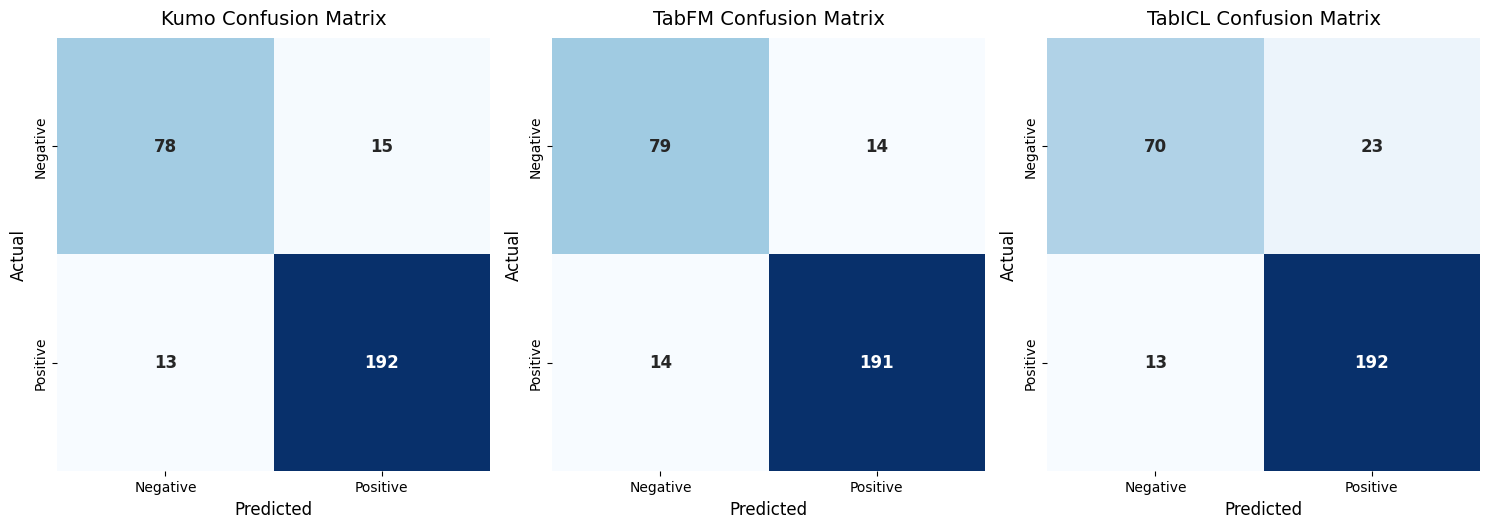

In [23]:
cm_kumo = confusion_matrix(y_test, y_pred_kumo)
cm_tabfm = confusion_matrix(y_test, y_pred_tabfm)
cm_tabicl = confusion_matrix(y_test, y_pred_tabicl)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

sns.heatmap(cm_kumo, annot=True, fmt='d', cmap='Blues', ax=axes[0], square=True, cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
            annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title('Kumo Confusion Matrix', fontsize=14, pad=10)
axes[0].set_xlabel('Predicted', fontsize=12)
axes[0].set_ylabel('Actual', fontsize=12)

sns.heatmap(cm_tabfm, annot=True, fmt='d', cmap='Blues', ax=axes[1], square=True, cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
            annot_kws={'size': 12, 'weight': 'bold'})
axes[1].set_title('TabFM Confusion Matrix', fontsize=14, pad=10)
axes[1].set_xlabel('Predicted', fontsize=12)
axes[1].set_ylabel('Actual', fontsize=12)

sns.heatmap(cm_tabicl, annot=True, fmt='d', cmap='Blues', ax=axes[2], square=True, cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
            annot_kws={'size': 12, 'weight': 'bold'})
axes[2].set_title('TabICL Confusion Matrix', fontsize=14, pad=10)
axes[2].set_xlabel('Predicted', fontsize=12)
axes[2].set_ylabel('Actual', fontsize=12)

plt.tight_layout()
plt.show()